# Lesson 3: A neural network from scratch

The polynomial of Lesson 2 was linear in its coefficients, so one linear solve found the best ones. A neural network is not linear in its weights, so there is no formula: we compute the gradient of the loss with respect to every weight and walk downhill. This lesson writes every line of that in NumPy, with explicit matrices, and checks each piece.

1. One unit, one layer
2. What hidden units do
3. Starting weights, and why their spread is 1/√n_in
4. The forward pass, line by line
5. The loss
6. Backpropagation, line by line
7. Checking the gradient
8. The training loop, by hand
9. The learning rate

`emulator/numpy_mlp.py` holds the same code in reusable functions, and each section checks against it.

In [1]:
# 1. Let Python find the emulator package
import sys

sys.path.insert(0, "..")

# 2. Imports
import json
import time

import matplotlib.pyplot as plt
import numpy as np

from emulator import data, evaluate, numpy_mlp
from emulator.evaluate import PALETTE

# 3. Load, split and transform (Lesson 1)
grid = data.load_grid("../training_250k.h5")
inputs, outputs, output_names = grid["inputs"], grid["outputs"], grid["output_names"]
indices = data.split_from_labels(grid["split"])
train, val = indices["train"], indices["val"]
input_transform = data.fit_input_transform(inputs[train])
output_transform = data.fit_output_transform(outputs[train])
x_train = data.transform_inputs(inputs[train], input_transform)  # (200000, 6)
x_val = data.transform_inputs(inputs[val], input_transform)  # (25000, 6)
y_train = data.transform_outputs(outputs[train], output_transform)  # (200000, 19)
y_val = data.transform_outputs(outputs[val], output_transform)  # (25000, 19)

## 1. One unit, one layer

A hidden **unit** takes the weighted sum of its inputs plus a bias and passes it through a smooth step, here tanh:

$$ z = \sum_{k} x_k w_k + b, \qquad a = \tanh(z) . $$

A **layer** of n units does this n times with n weight vectors, which for a whole batch of B models is one matrix product. With the batch in the rows of X (B × D), the weights in the columns of W (D × n) and one bias per unit in b (n):

$$ Z = X W + \mathbb{1} b^{\mathsf T} \quad (B \times n), \qquad A = \tanh(Z) \quad \text{element by element.} $$

Entry $Z_{ij}$ is unit *j*'s weighted sum for model *i*. Stacking layers, each taking the previous layer's A as its input, gives the network.

## 2. What hidden units do

Take one input x and one output, with n hidden units in between:

$$ y(x) = c + \sum_{j=1}^{n} v_j \tanh(w_j x + b_j) . $$

Each unit is a smooth step whose position is −b/w and whose steepness is w, and training adjusts every w, b, v and c. Below, a toy curve with the two features seen in Lesson 1: a small step and a cliff onto a floor. (These fits use `numpy_mlp.train_sgd`, the training loop that Section 8 writes out by hand.)

In [2]:
# 1. The toy curve: a small step near x = 0.5 and a cliff onto a floor for x < 0
x_toy = np.linspace(-1, 1, 400)[:, None]
step = -1.5 / (1.0 + np.exp(-(x_toy - 0.5) / 0.04))
y_toy = np.where(x_toy > 0.0, -3.5 + step, -3.5 + 40.0 * x_toy)
y_toy = np.maximum(y_toy, -30.0)

# 2. Standardize it, as we do for the real outputs
toy_mean, toy_std = y_toy.mean(), y_toy.std()
y_toy_scaled = (y_toy - toy_mean) / toy_std

# 3. Fit networks with 1, 3 and 30 hidden units
toy_fits = {}
for n_units in [1, 3, 30]:
    params = numpy_mlp.init_params([1, n_units, 1], seed=1)
    params, history = numpy_mlp.train_sgd(
        params,
        x_toy,
        y_toy_scaled,
        x_toy,
        y_toy_scaled,
        learning_rate=0.1,
        batch_size=20,
        n_epochs=10000,
    )
    toy_fits[n_units] = params
    print(f"{n_units:2d} units: final loss {history['train_loss'][-1]:.1e}")

 1 units: final loss 6.6e-03


 3 units: final loss 1.6e-03


30 units: final loss 5.2e-04


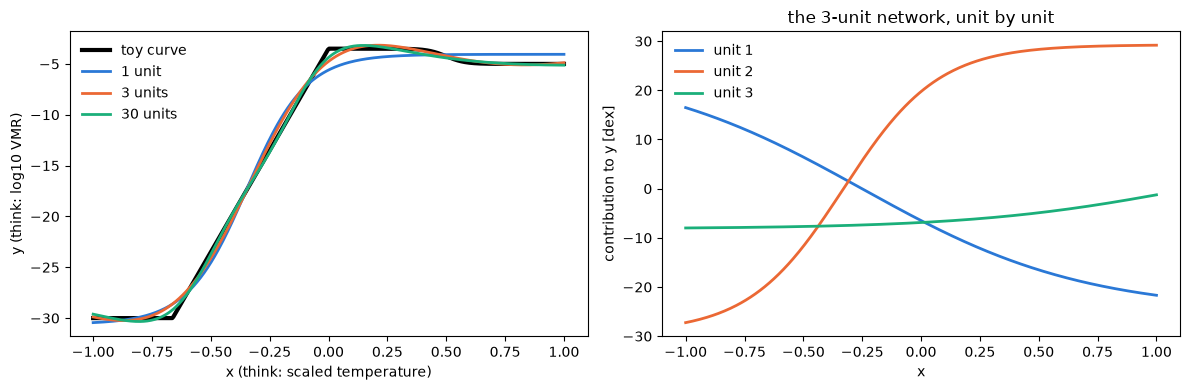

In [3]:
# 1. Data and the three fits
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x_toy, y_toy, color="black", lw=3, label="toy curve")
for colour, (n_units, params) in zip(PALETTE, toy_fits.items()):
    fit = numpy_mlp.forward(params, x_toy)[0] * toy_std + toy_mean
    axes[0].plot(
        x_toy,
        fit,
        color=colour,
        lw=2,
        label=f"{n_units} unit" + ("s" if n_units > 1 else ""),
    )
axes[0].set(xlabel="x (think: scaled temperature)", ylabel="y (think: log10 VMR)")
axes[0].legend(frameon=False)

# 2. The 3-unit network taken apart: each unit's contribution v_j tanh(w_j x + b_j)
params = toy_fits[3]
hidden = np.tanh(x_toy @ params[0]["W"] + params[0]["b"])
for unit in range(3):
    contribution = hidden[:, unit] * params[1]["W"][unit, 0] * toy_std
    axes[1].plot(
        x_toy, contribution, color=PALETTE[unit], lw=2, label=f"unit {unit + 1}"
    )
axes[1].set(
    xlabel="x",
    ylabel="contribution to y [dex]",
    title="the 3-unit network, unit by unit",
)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

One unit can make one step, so it spends itself on the cliff and misses the small step near x = 0.5. Three units capture both, and thirty sharpen the corners. The units do not split the work the way you would by hand (two of them are large and partly cancel), because many sets of weights give nearly the same curve and training only has to find one of them. **A network is a sum of adjustable steps, and with enough of them it can approximate any reasonable function** (the *universal approximation theorem*).

## 3. Starting weights, and why their spread is 1/√n_in

Before training the weights are random, and their spread matters. A unit adds up $n_{\text{in}}$ terms $a_k w_k$, and if the weights are independent with mean zero and variance $s^2$,

$$ \mathrm{Var}(z) = n_{\text{in}}\, s^2\, \mathrm{E}[a^2] . $$

Choosing $s^2 = 1/n_{\text{in}}$ makes $\mathrm{Var}(z) = \mathrm{E}[a^2]$, so the signal keeps its size from layer to layer (LeCun initialization). A smaller spread shrinks the signal geometrically with depth, and a larger one pushes tanh into saturation at ±1, where its derivative $1 - a^2$ is zero and gradients cannot flow back. Here are eight layers of 256 units:

0.5 / sqrt(n_in)         std of the signal after 8 layers 0.002, saturated units 0%


1 / sqrt(n_in) (LeCun)   std of the signal after 8 layers 0.237, saturated units 0%
2 / sqrt(n_in)           std of the signal after 8 layers 0.727, saturated units 7%


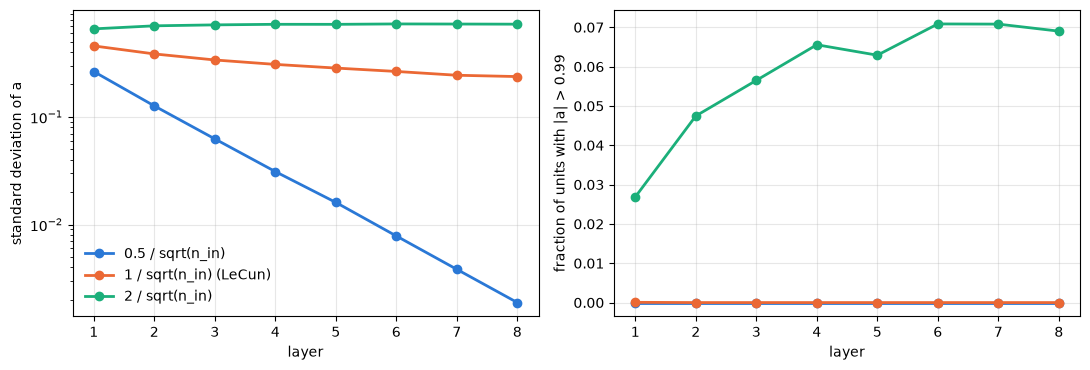

In [4]:
# 1. Push 2,000 training models through 8 tanh layers, for three weight spreads
rng = np.random.default_rng(0)
spreads = {
    "0.5 / sqrt(n_in)": 0.5,
    "1 / sqrt(n_in) (LeCun)": 1.0,
    "2 / sqrt(n_in)": 2.0,
}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for colour, (label, factor) in zip(PALETTE, spreads.items()):
    a = x_train[:2000]  # (2000, 6)
    signal, saturated = [], []
    for layer in range(8):
        n_in = a.shape[1]
        W = rng.normal(0.0, factor / np.sqrt(n_in), size=(n_in, 256))
        a = np.tanh(a @ W)  # (2000, 256)
        signal.append(a.std())
        saturated.append(np.mean(np.abs(a) > 0.99))

    # 1a. Plot the size of the signal and the fraction of saturated units
    axes[0].plot(range(1, 9), signal, "o-", color=colour, lw=2, label=label)
    axes[1].plot(range(1, 9), saturated, "o-", color=colour, lw=2, label=label)
    print(
        f"{label:24s} std of the signal after 8 layers {signal[-1]:.3f}, saturated units {100 * saturated[-1]:.0f}%"
    )

# 2. Labels
axes[0].set(xlabel="layer", ylabel="standard deviation of a", yscale="log")
axes[1].set(xlabel="layer", ylabel="fraction of units with |a| > 0.99")
axes[0].legend(frameon=False)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

With tanh the LeCun signal still shrinks slowly, because |tanh(z)| < |z|, but after eight layers it keeps a spread of 0.24. Half that weight spread leaves 0.002, so later layers see almost nothing, and double the spread drives 7% of the units into saturation, where they stop passing gradients back.

## 4. The forward pass, line by line

The network for our data has two hidden layers of 64 units:

$$ A_1 = \tanh(X W_1 + \mathbb{1} b_1^{\mathsf T}), \qquad A_2 = \tanh(A_1 W_2 + \mathbb{1} b_2^{\mathsf T}), \qquad \hat Y = A_2 W_3 + \mathbb{1} b_3^{\mathsf T} . $$

The output layer has no tanh, so the outputs can take any value. Here it is for one batch of 256 training models, with the shape of every array:

In [5]:
# 1. Starting weights, drawn layer by layer with spread 1/sqrt(n_in), biases zero
init_rng = np.random.default_rng(0)
W1 = init_rng.normal(0.0, 1.0 / np.sqrt(6), size=(6, 64))
W2 = init_rng.normal(0.0, 1.0 / np.sqrt(64), size=(64, 64))
W3 = init_rng.normal(0.0, 1.0 / np.sqrt(64), size=(64, 19))
b1, b2, b3 = np.zeros(64), np.zeros(64), np.zeros(19)
print("trainable numbers:", sum(p.size for p in (W1, b1, W2, b2, W3, b3)))

# 2. One batch
x = x_train[:256]  # (256, 6)
y = y_train[:256]  # (256, 19)

# 3. Forward pass
z1 = x @ W1 + b1  # (256, 64)
a1 = np.tanh(z1)  # (256, 64)
z2 = a1 @ W2 + b2  # (256, 64)
a2 = np.tanh(z2)  # (256, 64)
y_hat = a2 @ W3 + b3  # (256, 19)
for name, array in [("x", x), ("z1, a1", a1), ("z2, a2", a2), ("y_hat", y_hat)]:
    print(f"{name:7s} {array.shape}")

trainable numbers: 5843
x       (256, 6)
z1, a1  (256, 64)
z2, a2  (256, 64)
y_hat   (256, 19)


**Check** against the package, which draws the same starting weights for the same seed:

In [6]:
params = numpy_mlp.init_params([6, 64, 64, 19], seed=0)
y_hat_package, _ = numpy_mlp.forward(params, x)
print(
    "same W1:",
    np.array_equal(params[0]["W"], W1),
    "   largest output difference:",
    np.abs(y_hat_package - y_hat).max(),
)

same W1: True    largest output difference: 0.0


## 5. The loss

$$ L = \frac{1}{BK} \sum_{i=1}^{B} \sum_{k=1}^{K} (\hat Y_{ik} - Y'_{ik})^2 = \frac{\lVert \hat Y - Y' \rVert_F^2}{BK} $$

Up to a constant, this mean squared error is minus the log-likelihood of Gaussian errors with σ = 1 in standardized units, so training a network is maximum-likelihood fitting with thousands of parameters. With random weights the loss is about 1, the size of the data's own spread:

In [7]:
loss = np.mean((y_hat - y) ** 2)
print("loss with random weights:", loss)

loss with random weights: 1.1474740947788498


## 6. Backpropagation, line by line

We need $\partial L / \partial W$ and $\partial L / \partial b$ for every layer. Write Δ = ∂L/∂Z for a layer's values before the tanh. In index notation one layer is $Z_{ij} = \sum_k A_{ik} W_{kj} + b_j$, and the chain rule gives three rules:

$$ \frac{\partial L}{\partial W_{kj}} = \sum_i \Delta_{ij} A_{ik} \;\Rightarrow\; \frac{\partial L}{\partial W} = A^{\mathsf T} \Delta, \qquad \frac{\partial L}{\partial b_j} = \sum_i \Delta_{ij}, \qquad \frac{\partial L}{\partial A_{ik}} = \sum_j \Delta_{ij} W_{kj} \;\Rightarrow\; \frac{\partial L}{\partial A} = \Delta W^{\mathsf T} . $$

The tanh acts element by element and $\tanh'(z) = 1 - \tanh^2(z) = 1 - a^2$, so passing back through it is an element-wise product: $\partial L/\partial Z = (\partial L/\partial A) \odot (1 - A^2)$. Starting from the loss and walking back:

$$ \Delta_3 = \frac{2(\hat Y - Y')}{BK}, \quad \frac{\partial L}{\partial W_3} = A_2^{\mathsf T} \Delta_3, \quad \Delta_2 = (\Delta_3 W_3^{\mathsf T}) \odot (1 - A_2^2), \quad \frac{\partial L}{\partial W_2} = A_1^{\mathsf T} \Delta_2, \quad \Delta_1 = (\Delta_2 W_2^{\mathsf T}) \odot (1 - A_1^2), \quad \frac{\partial L}{\partial W_1} = X^{\mathsf T} \Delta_1 . $$

Every gradient has the shape of its weight, and each layer costs two matrix products, so the backward pass costs about two forward passes.

In [8]:
# 1. Output layer (no tanh)
d3 = 2.0 * (y_hat - y) / y.size  # dL/dz3 = dL/dy_hat, (256, 19)
gW3 = a2.T @ d3  # (64, 19)
gb3 = d3.sum(axis=0)  # (19,)

# 2. Second hidden layer: back through W3, then through the tanh
d2 = (d3 @ W3.T) * (1.0 - a2**2)  # (256, 64)
gW2 = a1.T @ d2  # (64, 64)
gb2 = d2.sum(axis=0)  # (64,)

# 3. First hidden layer
d1 = (d2 @ W2.T) * (1.0 - a1**2)  # (256, 64)
gW1 = x.T @ d1  # (6, 64)
gb1 = d1.sum(axis=0)  # (64,)

for name, gradient, weight in [
    ("W1", gW1, W1),
    ("b1", gb1, b1),
    ("W2", gW2, W2),
    ("b2", gb2, b2),
    ("W3", gW3, W3),
    ("b3", gb3, b3),
]:
    print(
        f"dL/d{name}: {str(gradient.shape):9s} (same as {name}: {gradient.shape == weight.shape})"
    )

dL/dW1: (6, 64)   (same as W1: True)
dL/db1: (64,)     (same as b1: True)
dL/dW2: (64, 64)  (same as W2: True)
dL/db2: (64,)     (same as b2: True)
dL/dW3: (64, 19)  (same as W3: True)
dL/db3: (19,)     (same as b3: True)


## 7. Checking the gradient

Hand-written gradients are easy to get wrong, so we test them against central finite differences: nudge one weight by ±h and see how much the loss changes,

$$ \frac{\partial L}{\partial w} \approx \frac{L(w + h) - L(w - h)}{2h} . $$

In [9]:
def batch_loss(
    W1,
    b1,
    W2,
    b2,
    W3,
    b3,
):
    """Loss of the 2-layer network on the batch (x, y) defined above.

    Parameters
    ----------
    W1, b1, W2, b2, W3, b3 : ndarray
        Weights and biases of the three layers.

    Returns
    -------
    loss : float
        Mean squared error on the batch.
    """
    y_pred = np.tanh(np.tanh(x @ W1 + b1) @ W2 + b2) @ W3 + b3
    loss = float(np.mean((y_pred - y) ** 2))
    return loss


# 1. Nudge a few weights and compare with the backpropagation result
h = 1e-6
weights = {"W1": W1, "b1": b1, "W2": W2, "b2": b2, "W3": W3, "b3": b3}
gradients = {"W1": gW1, "b1": gb1, "W2": gW2, "b2": gb2, "W3": gW3, "b3": gb3}
for name, position in [
    ("W1", (2, 5)),
    ("b1", (7,)),
    ("W2", (10, 3)),
    ("b2", (40,)),
    ("W3", (7, 11)),
    ("b3", (18,)),
]:
    original = weights[name][position]
    weights[name][position] = original + h
    loss_up = batch_loss(**weights)
    weights[name][position] = original - h
    loss_down = batch_loss(**weights)
    weights[name][position] = original
    finite_difference = (loss_up - loss_down) / (2.0 * h)
    print(
        f"{name}{position}: backprop {gradients[name][position]: .8e}   finite difference {finite_difference: .8e}"
    )

W1(2, 5): backprop  3.84120220e-04   finite difference  3.84120069e-04
b1(7,): backprop -1.07318400e-03   finite difference -1.07318399e-03
W2(10, 3): backprop -5.39299469e-03   finite difference -5.39299461e-03
b2(40,): backprop -2.00599680e-03   finite difference -2.00599681e-03
W3(7, 11): backprop -1.35979744e-02   finite difference -1.35979745e-02
b3(18,): backprop  3.49653632e-03   finite difference  3.49653628e-03


Agreement to about seven significant figures, the precision of a central difference with h = 10⁻⁶. **Check** against the package too:

In [10]:
_, activations = numpy_mlp.forward(params, x)
grads_package = numpy_mlp.backward(params, activations, y_hat_package, y)
print("largest difference in dL/dW1:", np.abs(grads_package[0]["W"] - gW1).max())
print("largest difference in dL/dW3:", np.abs(grads_package[2]["W"] - gW3).max())

largest difference in dL/dW1: 0.0
largest difference in dL/dW3: 0.0


## 8. The training loop, by hand

Gradient descent moves every weight a small step downhill, $\theta \leftarrow \theta - \eta\, \partial L/\partial\theta$, where η is the **learning rate**. Each step uses a random **mini-batch** of 256 models, whose gradient is a noisy but unbiased estimate of the gradient over all 200,000. One pass through the data in random order is an **epoch**, and the whole procedure is *stochastic gradient descent* (SGD). Here it is in full: shuffle, then for every batch the forward pass, the backward pass and the update.

In [11]:
# 1. Settings and starting weights (the same draws as in Section 4)
learning_rate, batch_size, n_epochs = 0.3, 256, 20
init_rng = np.random.default_rng(0)
W1 = init_rng.normal(0.0, 1.0 / np.sqrt(6), size=(6, 64))
W2 = init_rng.normal(0.0, 1.0 / np.sqrt(64), size=(64, 64))
W3 = init_rng.normal(0.0, 1.0 / np.sqrt(64), size=(64, 19))
b1, b2, b3 = np.zeros(64), np.zeros(64), np.zeros(19)
shuffle_rng = np.random.default_rng(0)
val_losses = []

# 2. The loop
start = time.perf_counter()
for epoch in range(n_epochs):
    order = shuffle_rng.permutation(len(x_train))
    for begin in range(0, len(order), batch_size):
        batch = order[begin : begin + batch_size]
        x, y = x_train[batch], y_train[batch]

        # 2a. Forward pass
        a1 = np.tanh(x @ W1 + b1)
        a2 = np.tanh(a1 @ W2 + b2)
        y_hat = a2 @ W3 + b3

        # 2b. Backward pass (all deltas before any weight changes)
        d3 = 2.0 * (y_hat - y) / y.size
        d2 = (d3 @ W3.T) * (1.0 - a2**2)
        d1 = (d2 @ W2.T) * (1.0 - a1**2)

        # 2c. Gradient-descent update
        W3 -= learning_rate * (a2.T @ d3)
        b3 -= learning_rate * d3.sum(axis=0)
        W2 -= learning_rate * (a1.T @ d2)
        b2 -= learning_rate * d2.sum(axis=0)
        W1 -= learning_rate * (x.T @ d1)
        b1 -= learning_rate * d1.sum(axis=0)

    # 2d. Validation loss at the end of the epoch
    y_val_hat = np.tanh(np.tanh(x_val @ W1 + b1) @ W2 + b2) @ W3 + b3
    val_losses.append(np.mean((y_val_hat - y_val) ** 2))
print(
    f"{n_epochs} epochs in {time.perf_counter() - start:.0f} s; validation loss {val_losses[0]:.4f} -> {val_losses[-1]:.4f}"
)

20 epochs in 5 s; validation loss 0.0772 -> 0.0079


**Check**: the package's `train_sgd`, started from the same weights and shuffled with the same seed, ends at the same weights:

largest difference in W1 after training: 0.0
largest difference in W3 after training: 0.0


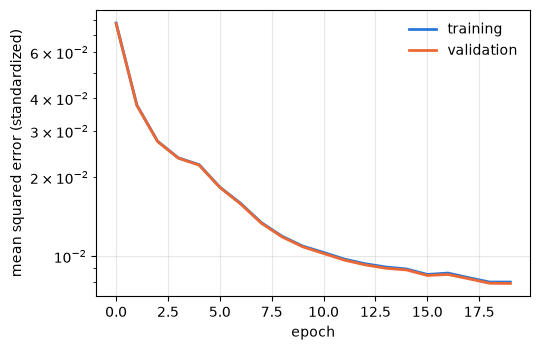

In [12]:
params_package, history = numpy_mlp.train_sgd(
    numpy_mlp.init_params([6, 64, 64, 19], seed=0),
    x_train,
    y_train,
    x_val,
    y_val,
    learning_rate=0.3,
    batch_size=256,
    n_epochs=20,
)
print(
    "largest difference in W1 after training:",
    np.abs(params_package[0]["W"] - W1).max(),
)
print(
    "largest difference in W3 after training:",
    np.abs(params_package[2]["W"] - W3).max(),
)

# 1. Loss curves
fig = evaluate.plot_history(history)
plt.show()

In [13]:
# 1. Errors in dex on the validation set
log10_pred = data.inverse_transform_outputs(y_val_hat, output_transform)
numpy_scores = evaluate.summary_errors(outputs[val], log10_pred)

# 2. Compare with Lesson 2
with open("../runs/baseline_scores.json") as handle:
    scores = json.load(handle)
scores["NumPy network, SGD, 20 epochs"] = numpy_scores
for name, score in scores.items():
    print(f"{name:30s} median {score['median']:.4f} dex   99% {score['p99']:.3f} dex")

mean                           median 9.5135 dex   99% 15.398 dex
linear                         median 3.3587 dex   99% 8.094 dex
polynomial, degree 1           median 3.3587 dex   99% 8.094 dex
polynomial, degree 2           median 2.5986 dex   99% 7.081 dex
polynomial, degree 3           median 1.4586 dex   99% 4.636 dex
polynomial, degree 4           median 0.9077 dex   99% 3.619 dex
polynomial, degree 5           median 0.7193 dex   99% 3.029 dex
nearest neighbours, k=1        median 0.3736 dex   99% 5.694 dex
nearest neighbours, k=8        median 0.2910 dex   99% 3.008 dex
nearest neighbours, k=32       median 0.3979 dex   99% 2.900 dex
NumPy network, SGD, 20 epochs  median 0.2873 dex   99% 1.924 dex


A network with 5,843 numbers, trained for 20 epochs with plain SGD in a few seconds, already matches nearest neighbours on the typical error and beats every baseline on the bad cases (the 99% column). The loss is still falling, so the network is not done learning, and Lesson 4 makes training much faster.

## 9. The learning rate

The learning rate is the most important setting in training. With too small a rate the loss creeps down, and with too large a rate each step jumps across the valley instead of down it, so the loss stalls and bounces.

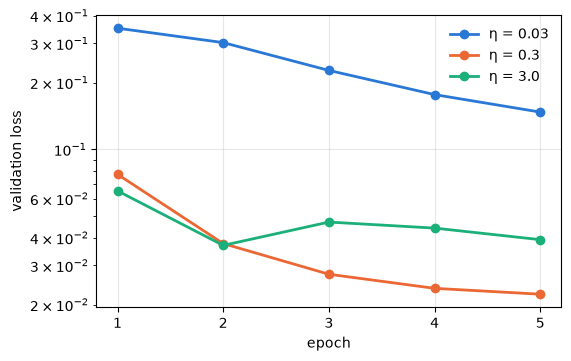

In [14]:
# 1. Five epochs at three learning rates, from the same starting weights
fig, ax = plt.subplots(figsize=(6, 3.8))
for colour, rate in zip(PALETTE, [0.03, 0.3, 3.0]):
    _, history = numpy_mlp.train_sgd(
        numpy_mlp.init_params([6, 64, 64, 19], seed=0),
        x_train,
        y_train,
        x_val,
        y_val,
        learning_rate=rate,
        batch_size=256,
        n_epochs=5,
    )
    ax.plot(
        np.arange(1, 6),
        history["val_loss"],
        "o-",
        color=colour,
        lw=2,
        label=f"η = {rate}",
    )
ax.set(xlabel="epoch", ylabel="validation loss", yscale="log")
ax.set_xticks(range(1, 6))
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

## Exercises

1. Replace tanh by ReLU, max(0, z). Change the activation in the forward pass and its derivative in the backward pass (1 where z > 0 and 0 elsewhere), then rerun the gradient check before training.
2. Add a third hidden layer by hand: one more W, b, forward line and backward line. Which lines of the loop change?
3. Add momentum: keep a velocity for each weight, v ← 0.9 v − η g, and update θ ← θ + v. Does it train faster?
4. Make the hidden layers 16 or 128 units wide. How do the training time and the error change?